In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
from google.colab import userdata
import os
github_token = userdata.get('Git_Key')
owner = 'No1MustardSeed' # Replace with the GitHub repository owner
repository = 'MSSPDA6070' # Replace with the GitHub repository name
clone_url = f'https://{github_token}@github.com/{owner}/{repository}/Data.git'
# Clone the repository
import subprocess
subprocess.run(['git', 'clone', clone_url])
# Navigate into the cloned repository directory (optional, but often useful)
clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'
result = subprocess.run(['git', 'clone', clone_url], capture_output=True, text=True)
print(result.returncode)
print(result.stderr)

import os
print(os.getcwd())
print(os.listdir('.'))

0
Cloning into 'MSSPDA6070'...

/content
['.config', 'MSSPDA6070', 'sample_data']


1. Use Google Colabs and Python to create a bar chart of yearly sales from the Internet Sales Data SetDownload Internet Sales Data Set.

2. Save the active figure to a file in PDF format.

3. Upload the Jupyter Notebook and data files PARTICIPATION ACTIVITY Week 7 assignment in Canvas.

4. Save your Notebooks and data files to your MSSP607 GitHub repository and share your repository with the instructor and the TAs as collaborators.


*   make sure you do the magic command for making it show in the window
*   data = np.arange(10) plt.plot(data)
*   convert array to series or series to array
*   covery data to make sure we send the right thing
*   define plot area fig = plt.figure() makes size shape
*   ax1 = fig.addsubplot(2, 2, 1)  #can add more ax2,3,4...
*   close the figure when done, it is good practice
*   can do line stype, labels, color, marker with arguments and legends(make it in the right spot)
*   when u creta visualations they should reinforce what you are saying, if not, put in appedix
*   from datetime import date time, to use code for converting string to data
*   fig.savefig('path')
*   need to make it overwrite rather than virtually save, mount drive then code
*   can use plt.Rectangle, Curciel, etc (make place and size and color and translucency)
*   can do with pandas or seaborn too

In [2]:
df7 = pd.read_csv('/content/MSSPDA6070/Data/InternetSales.csv', encoding='latin1')
df7.head()

/tmp/ipykernel_706/1649257288.py:1: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df7 = pd.read_csv('/content/MSSPDA6070/Data/InternetSales.csv', encoding='latin1')


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.15,1912.15,3399.99,272.00,85.00,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.62,1265.62,2319.99,185.60,58.00,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.22,8.22,21.98,1.76,0.55,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.94,1481.94,2384.07,190.73,59.60,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.84,10.84,28.99,2.32,0.72,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [3]:
#parse OrderDate

from datetime import datetime
df7['OrderDate'] = pd.to_datetime(df7['OrderDate'])
df7['OrderYear'] = df7['OrderDate'].dt.year

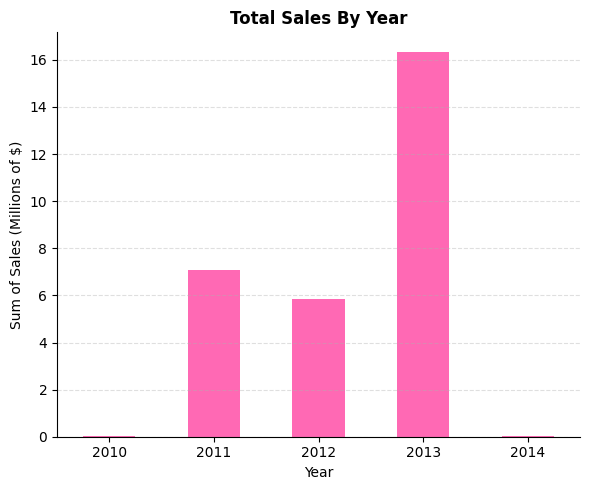

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
#making bar chart of sum of SalesAmount per year
#I wanted to use this as a reference for future project which is why I made modifications

import matplotlib.pyplot as plt

bar = df7.groupby("OrderYear")["SalesAmount"].sum() / 1000000

ax = bar.plot(kind = "bar", figsize = (6, 5), color = "hotpink")
ax.set_title("Total Sales By Year", fontweight = "bold")
ax.set_xlabel("Year")
ax.set_ylabel("Sum of Sales (Millions of $)")
ax.ticklabel_format(style="plain", axis="y")
ax.spines[["top", "right"]].set_visible(False) #made it not a box
ax.yaxis.grid(True, linestyle="--", alpha=0.4) #makes the line thingys go accross
plt.xticks(rotation = 0)
plt.tight_layout()
plt.savefig("w7bar.pdf", bbox_inches="tight")
plt.show()
plt.close()

from google.colab import files
files.download("w7bar.pdf")